In [1]:
#Importing the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
%matplotlib inline

In [2]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [3]:
data=pd.read_csv('/content/drive/MyDrive/Mall_Customers.csv')

In [4]:
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
data.corr(numeric_only=True)


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
CustomerID,1.000000,-0.026763,0.977548,0.013835
Age,-0.026763,1.000000,-0.012398,-0.327227
Annual Income (k$),0.977548,-0.012398,1.000000,0.009903
Spending Score (1-100),0.013835,-0.327227,0.009903,1.000000


Text(0, 0.5, 'Count')

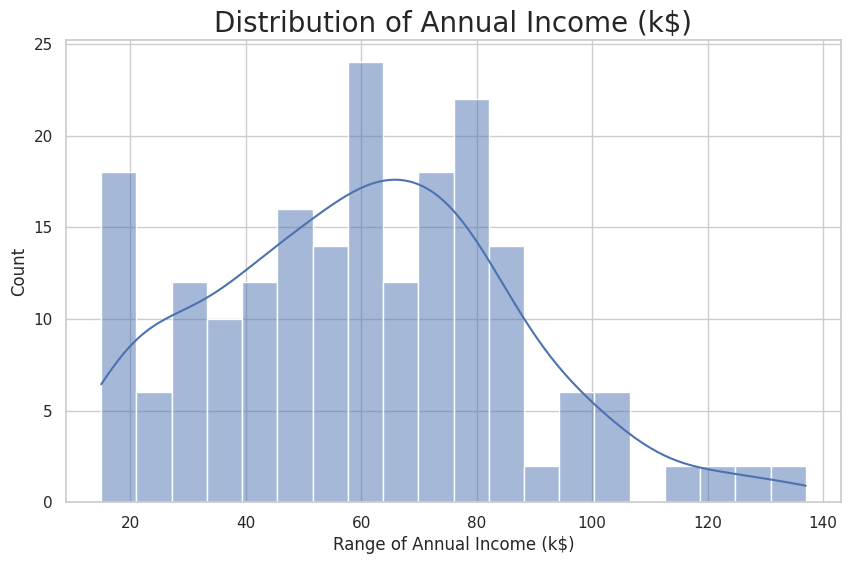

In [6]:
#Distribution of Annnual Income
plt.figure(figsize=(10, 6))
sns.set(style = 'whitegrid')
sns.histplot(data['Annual Income (k$)'], kde=True, bins=20)
plt.title('Distribution of Annual Income (k$)', fontsize = 20)
plt.xlabel('Range of Annual Income (k$)')
plt.ylabel('Count')

Text(0, 0.5, 'Count')

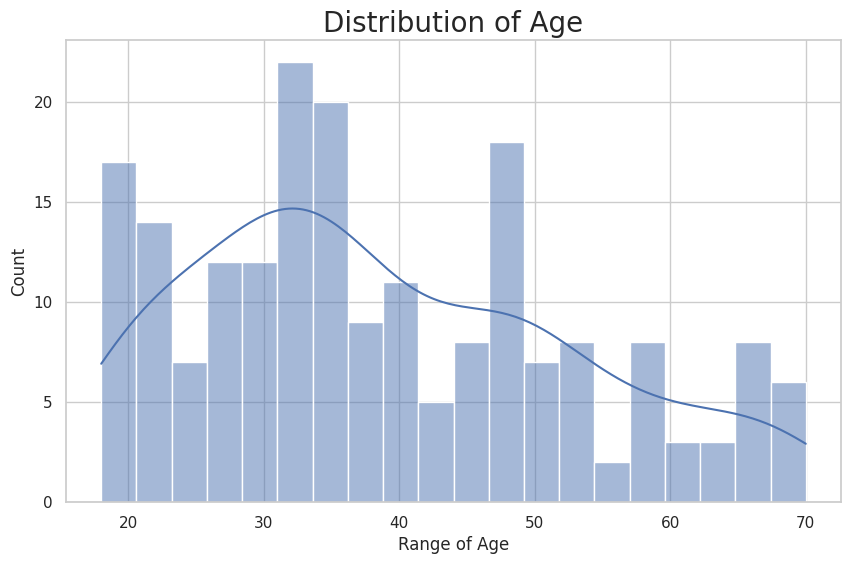

In [7]:
#Distribution of age
plt.figure(figsize=(10, 6))
sns.set(style = 'whitegrid')
sns.histplot(data['Age'], kde=True, bins=20)
plt.title('Distribution of Age', fontsize = 20)
plt.xlabel('Range of Age')
plt.ylabel('Count')

Text(0, 0.5, 'Count')

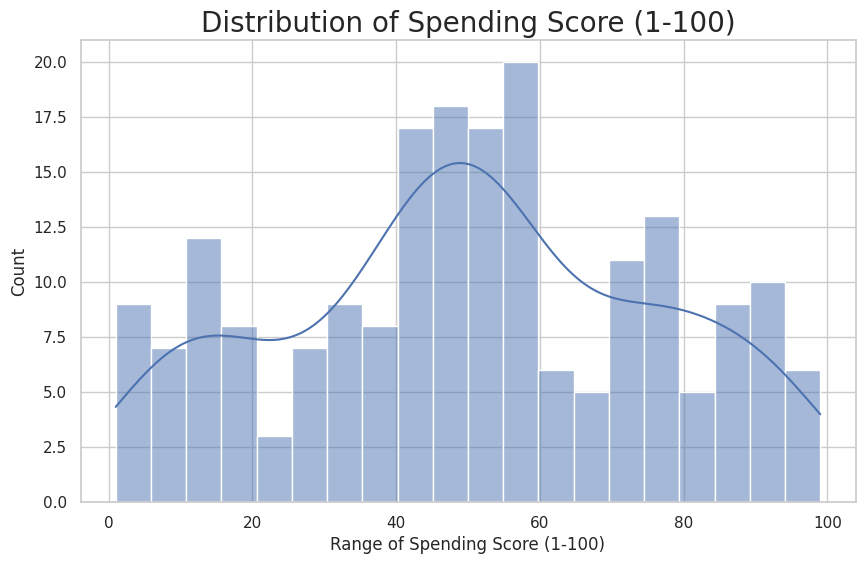

In [8]:
#Distribution of spending score
plt.figure(figsize=(10, 6))
sns.set(style = 'whitegrid')
sns.histplot(data['Spending Score (1-100)'], kde=True, bins=20)
plt.title('Distribution of Spending Score (1-100)', fontsize = 20)
plt.xlabel('Range of Spending Score (1-100)')
plt.ylabel('Count')

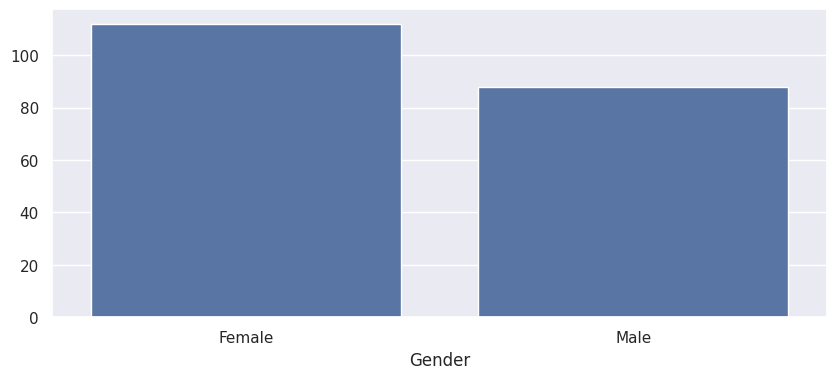

In [9]:
genders = data.Gender.value_counts()
sns.set_style("darkgrid")
plt.figure(figsize=(10,4))
sns.barplot(x=genders.index, y=genders.values)
plt.show()

## Extended EDA — understanding the dataset in more depth
Shortcuts used below: `INC` = Annual Income (k$), `SP` = Spending Score (1-100).

In [10]:
INC, SP = 'Annual Income (k$)', 'Spending Score (1-100)'
num_cols = ['Age', INC, SP]
print('Shape:', data.shape)
print('\nMissing values:\n', data.isnull().sum())
print('\nDuplicate rows:', data.duplicated().sum())
data.describe().round(2)

Shape: (200, 5)

Missing values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


### Outliers — boxplots

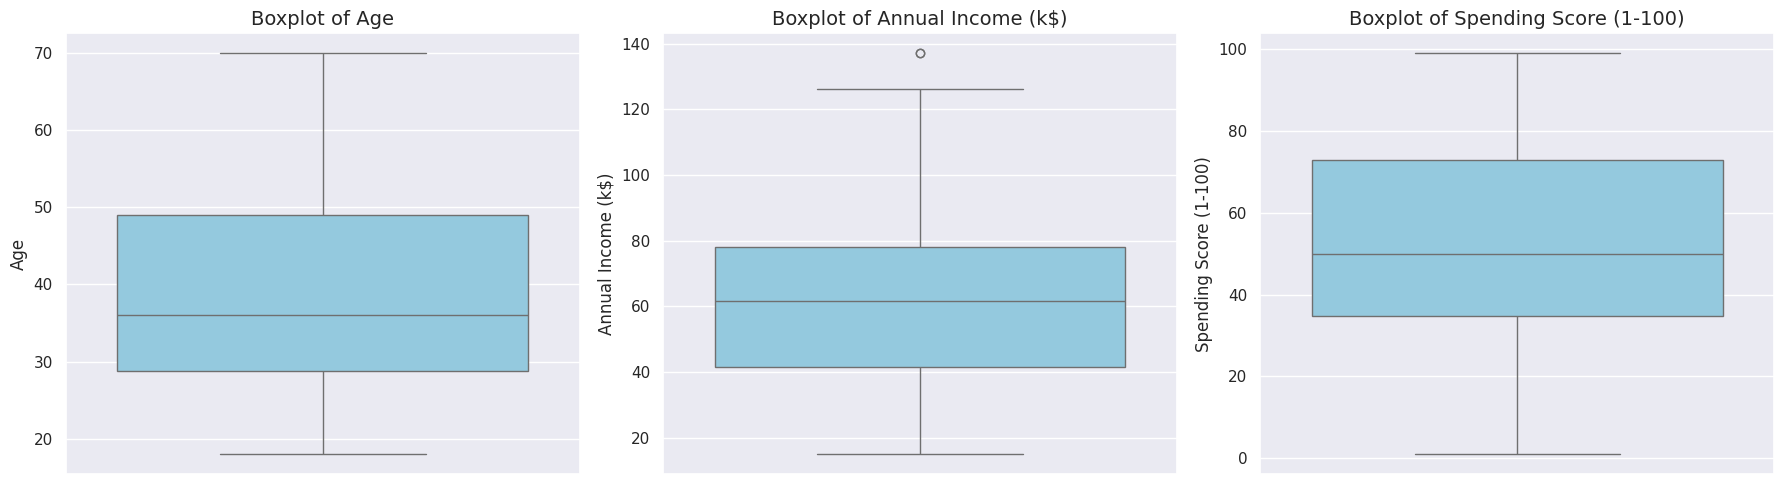

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=data[col], ax=ax, color='skyblue')
    ax.set_title(f'Boxplot of {col}', fontsize=14)
plt.tight_layout(); plt.show()

### Gender split — pie chart

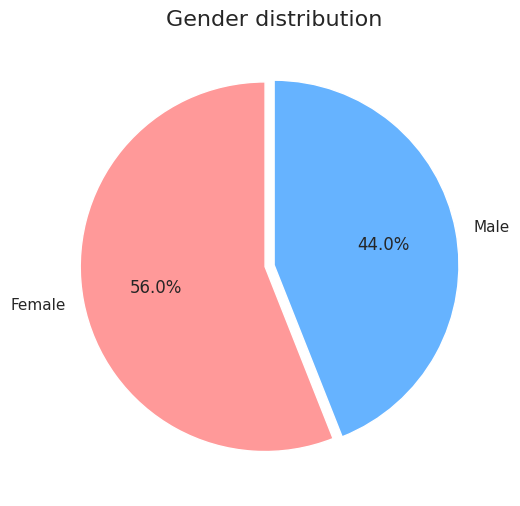

In [12]:
plt.figure(figsize=(6, 6))
data['Gender'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90,
                                      colors=['#ff9999', '#66b3ff'], explode=(0.05, 0))
plt.title('Gender distribution', fontsize=16); plt.ylabel(''); plt.show()

### Age groups — how many customers, and how much they earn and spend

/tmp/ipykernel_573/1695787531.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x='Age Group', y=INC, ax=axes[1], palette='Blues', errorbar=None)
/tmp/ipykernel_573/1695787531.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x='Age Group', y=SP, ax=axes[2], palette='Oranges', errorbar=None)


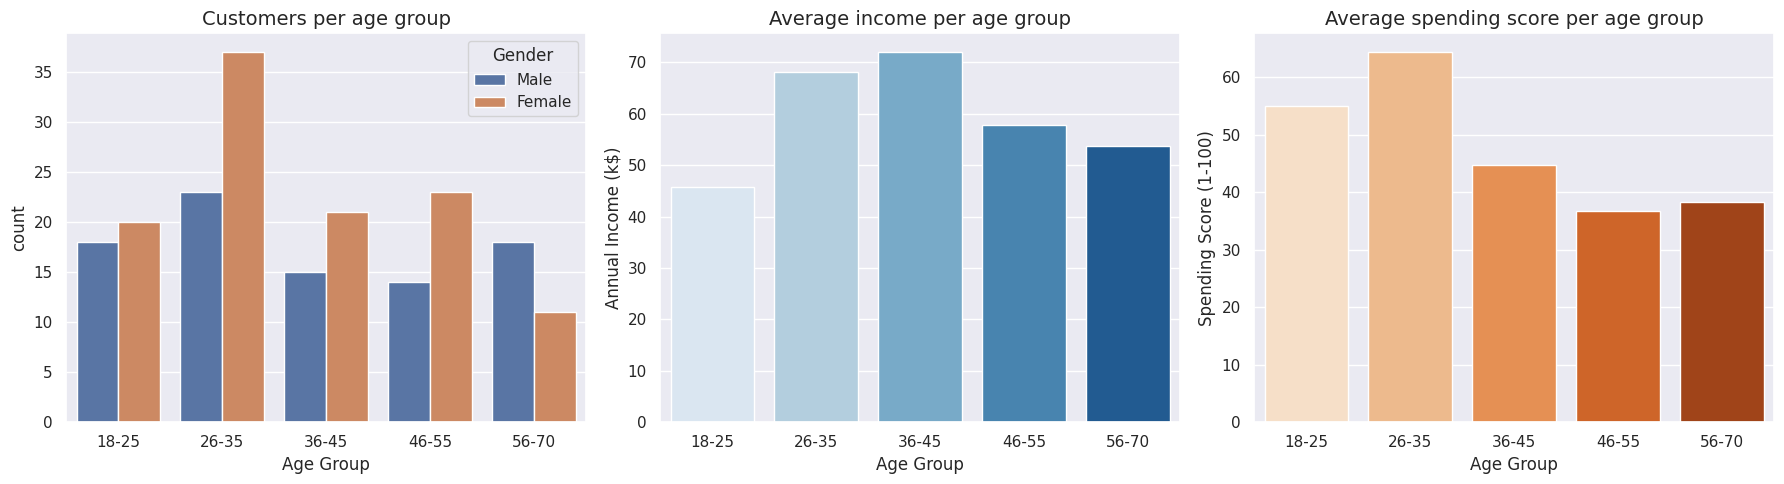

In [14]:
data['Age Group'] = pd.cut(data['Age'], bins=[17, 25, 35, 45, 55, 70],
                           labels=['18-25', '26-35', '36-45', '46-55', '56-70'])
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=data, x='Age Group', hue='Gender', ax=axes[0])
axes[0].set_title('Customers per age group', fontsize=14)
sns.barplot(data=data, x='Age Group', y=INC, ax=axes[1], palette='Blues', errorbar=None)
axes[1].set_title('Average income per age group', fontsize=14)
sns.barplot(data=data, x='Age Group', y=SP, ax=axes[2], palette='Oranges', errorbar=None)
axes[2].set_title('Average spending score per age group', fontsize=14)
plt.tight_layout(); plt.show()

### Relationships between features — regression lines

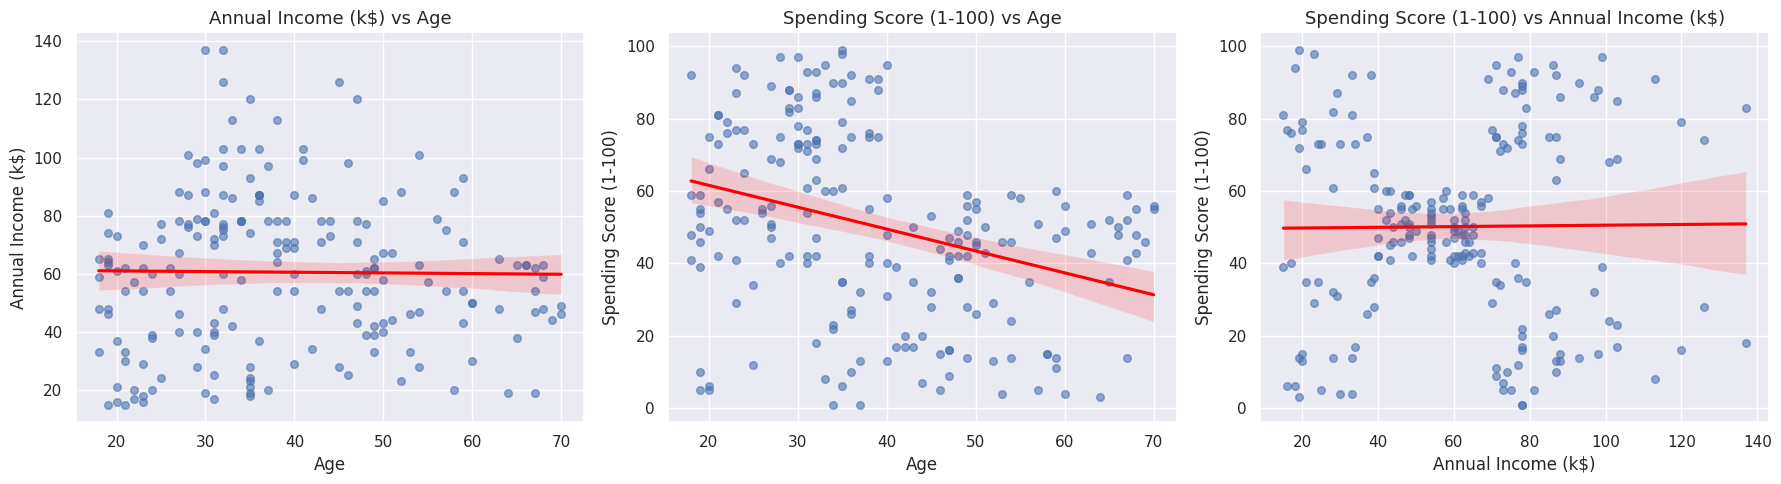

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [('Age', INC), ('Age', SP), (INC, SP)]
for ax, (x, y_) in zip(axes, pairs):
    sns.regplot(data=data, x=x, y=y_, ax=ax, scatter_kws={'s': 30, 'alpha': 0.6},
                line_kws={'color': 'red'})
    ax.set_title(f'{y_} vs {x}', fontsize=13)
plt.tight_layout(); plt.show()

### Pairplot by gender + correlation heatmap

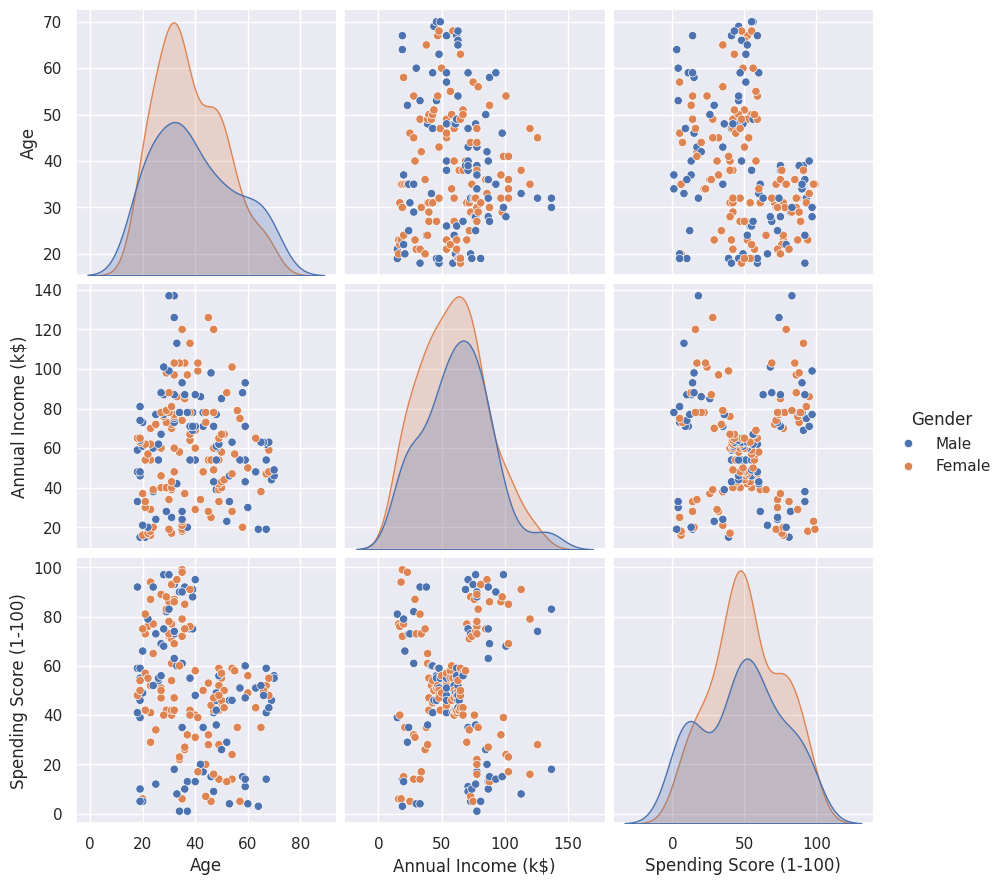

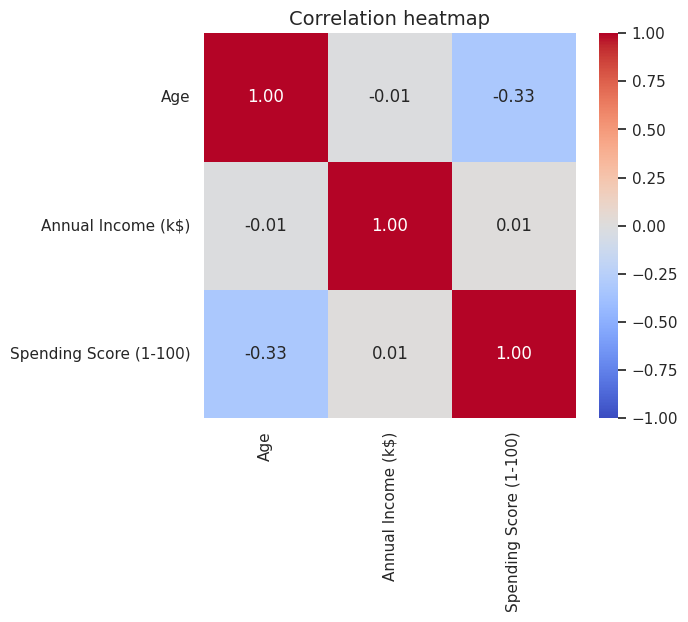

In [16]:
sns.pairplot(data[num_cols + ['Gender']], hue='Gender', diag_kind='kde', height=3)
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(data[num_cols].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation heatmap', fontsize=14); plt.show()

### Spending categories — who are the big spenders?

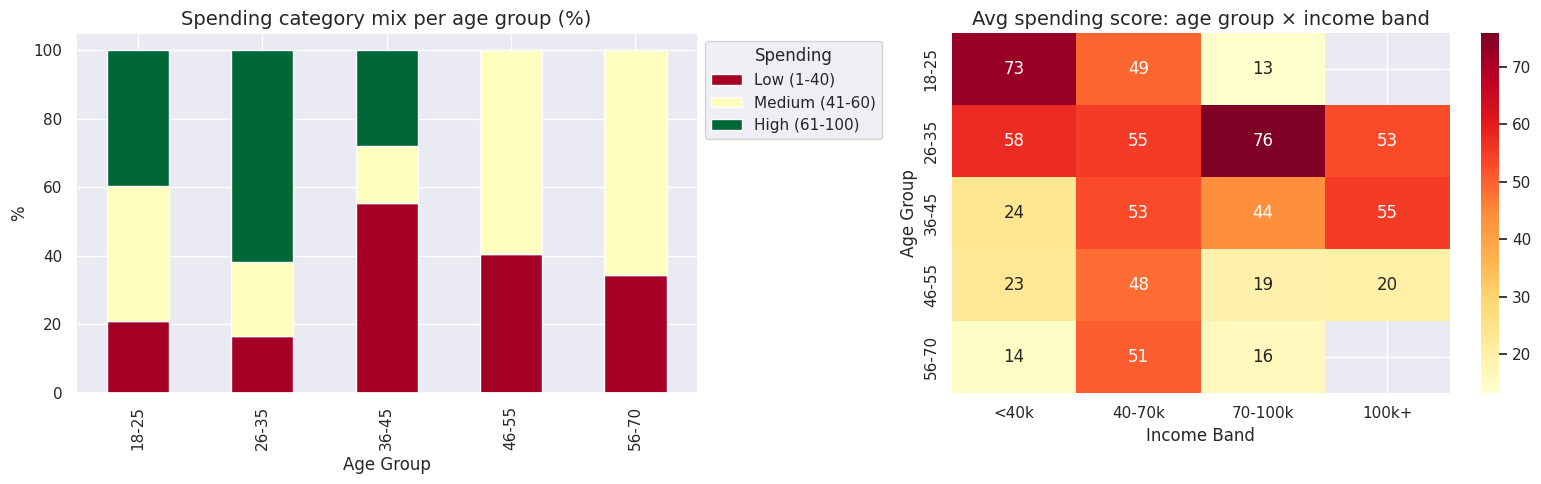

In [17]:
data['Spending Category'] = pd.cut(data[SP], bins=[0, 40, 60, 100],
                                   labels=['Low (1-40)', 'Medium (41-60)', 'High (61-100)'])
data['Income Band'] = pd.cut(data[INC], bins=[0, 40, 70, 100, 140],
                             labels=['<40k', '40-70k', '70-100k', '100k+'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pd.crosstab(data['Age Group'], data['Spending Category'], normalize='index').mul(100).plot(
    kind='bar', stacked=True, ax=axes[0], colormap='RdYlGn')
axes[0].set_title('Spending category mix per age group (%)', fontsize=14)
axes[0].set_ylabel('%'); axes[0].legend(title='Spending', bbox_to_anchor=(1, 1))

heat = data.pivot_table(index='Age Group', columns='Income Band', values=SP,
                        aggfunc='mean', observed=False)
sns.heatmap(heat, annot=True, fmt='.0f', cmap='YlOrRd', ax=axes[1])
axes[1].set_title('Avg spending score: age group × income band', fontsize=14)
plt.tight_layout(); plt.show()

### Density view of Income vs Spending — the clusters are already visible

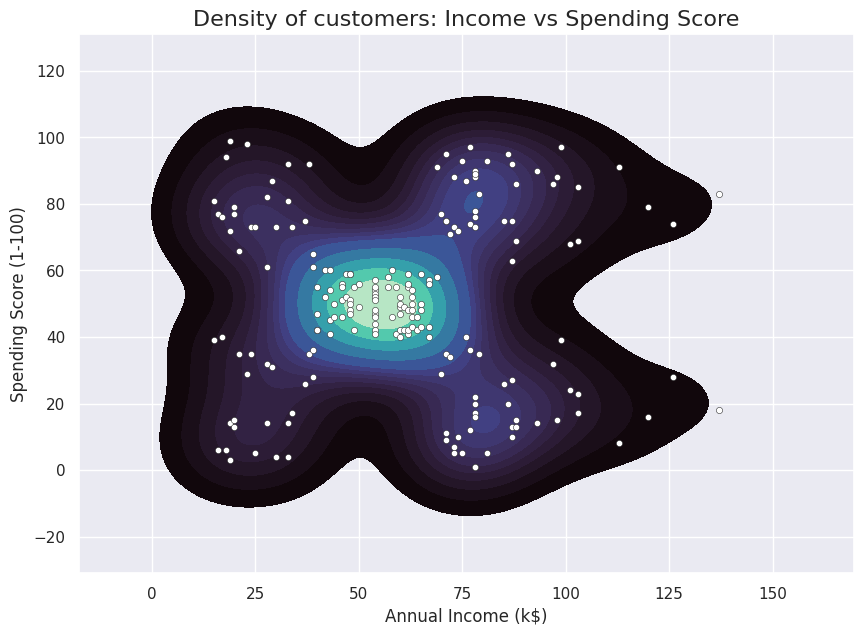

In [18]:
plt.figure(figsize=(10, 7))
sns.kdeplot(data=data, x=INC, y=SP, fill=True, cmap='mako', thresh=0.05, levels=15)
sns.scatterplot(data=data, x=INC, y=SP, color='white', s=20, edgecolor='k')
plt.title('Density of customers: Income vs Spending Score', fontsize=16); plt.show()

**EDA takeaways** (confirm against your plots):
- No missing values or duplicates; no extreme outliers apart from a few high incomes.
- Slightly more female than male customers; distributions are similar across genders.
- Younger customers (18–35) have clearly higher spending scores.
- Income and spending have ~0 correlation overall, yet the density plot shows ~5 dense pockets — a strong hint that 5 clusters will work.

In [19]:
df1=data[["CustomerID","Gender","Age","Annual Income (k$)","Spending Score (1-100)"]].copy()
X=df1[["Annual Income (k$)","Spending Score (1-100)"]]

In [20]:
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


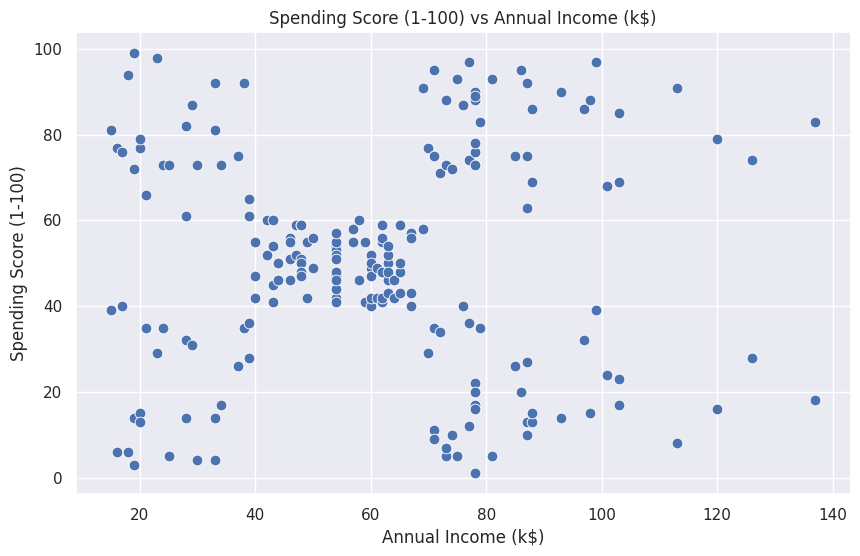

In [21]:
#Scatterplot of the input data
plt.figure(figsize=(10,6))
sns.scatterplot(x = 'Annual Income (k$)',y = 'Spending Score (1-100)',  data = X  ,s = 60 )
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Spending Score (1-100) vs Annual Income (k$)')
plt.show()

In [22]:
#Importing KMeans from sklearn
from sklearn.cluster import KMeans

In [23]:
wcss=[]
for i in range(1,11):
    km=KMeans(n_clusters=i)
    km.fit(X)
    wcss.append(km.inertia_)

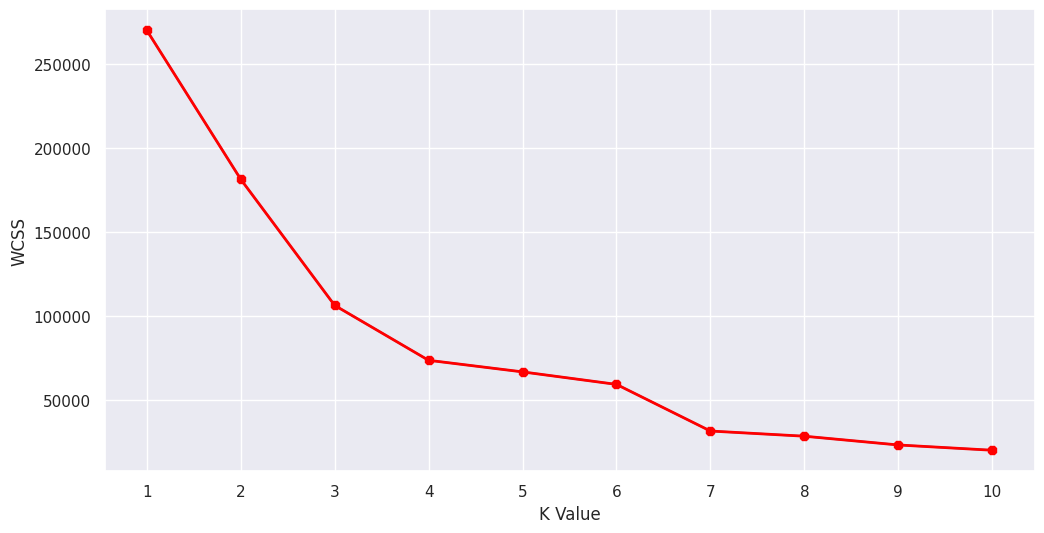

In [24]:
#The elbow curve
plt.figure(figsize=(12,6))
plt.plot(range(1,11),wcss)
plt.plot(range(1,11),wcss, linewidth=2, color="red", marker ="8")
plt.xlabel("K Value")
plt.xticks(np.arange(1,11,1))
plt.ylabel("WCSS")
plt.show()

In [25]:
#Taking 5 clusters (random_state makes the cluster numbers repeatable between runs)
km1=KMeans(n_clusters=5, n_init=10, random_state=42)
#Fitting the input data
km1.fit(X)
#predicting the labels of the input data
y=km1.predict(X)
#adding the labels to a column named label
df1["label"] = y
#Keep a permanent copy of the 2D clusters (the 3D model below overwrites "label")
df1["Cluster_2D"] = y
#The new dataframe with the clustering done
df1.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),label,Cluster_2D
0,1,Male,19,15,39,4,4
1,2,Male,21,15,81,2,2
2,3,Female,20,16,6,4,4
3,4,Female,23,16,77,2,2
4,5,Female,31,17,40,4,4


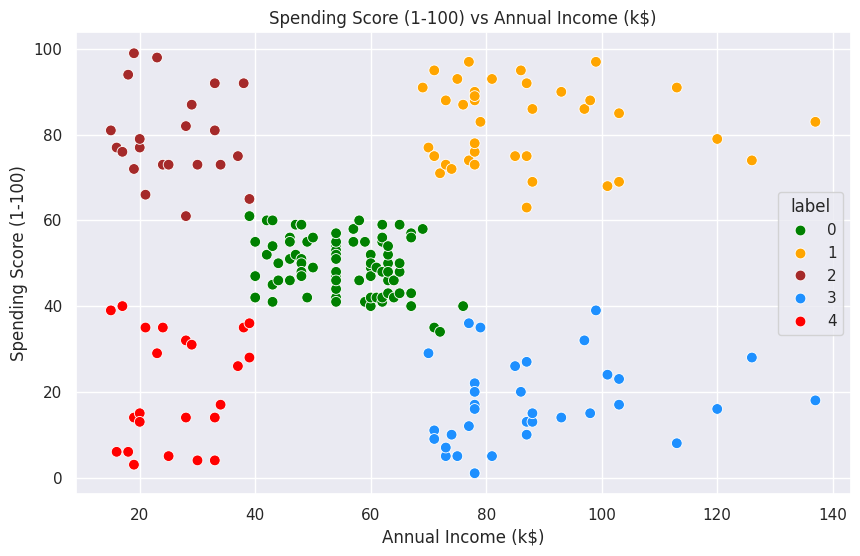

In [26]:
#Scatterplot of the clusters
plt.figure(figsize=(10,6))
sns.scatterplot(x = 'Annual Income (k$)',y = 'Spending Score (1-100)',hue="label",
                 palette=['green','orange','brown','dodgerblue','red'], legend='full',data = df1  ,s = 60 )
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Spending Score (1-100) vs Annual Income (k$)')
plt.show()

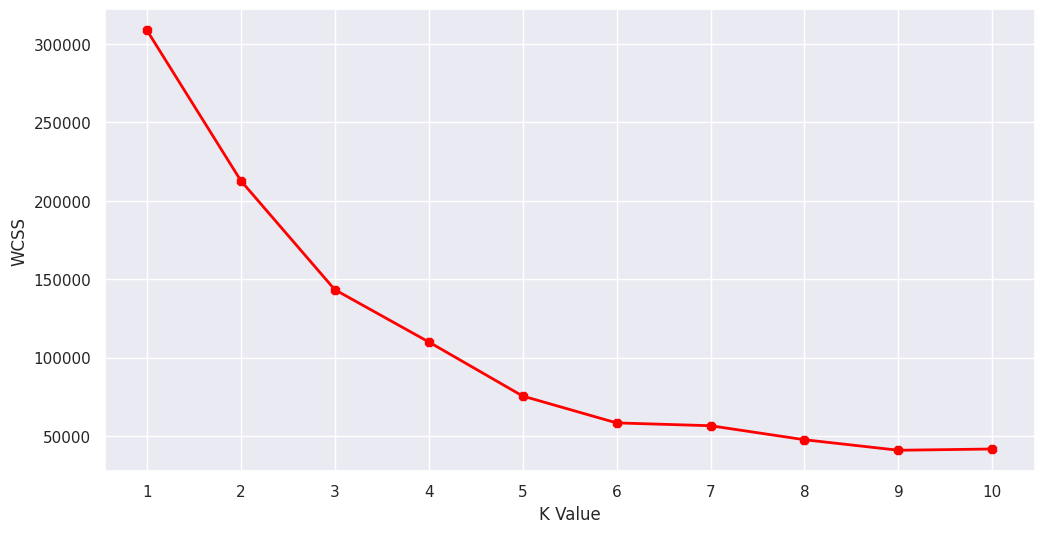

In [27]:
#Taking the features
X2=df1[["Age","Annual Income (k$)","Spending Score (1-100)"]]
#Now we calculate the Within Cluster Sum of Squared Errors (WSS) for different values of k.
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, init="k-means++")
    kmeans.fit(X2)
    wcss.append(kmeans.inertia_)
plt.figure(figsize=(12,6))
plt.plot(range(1,11),wcss, linewidth=2, color="red", marker ="8")
plt.xlabel("K Value")
plt.xticks(np.arange(1,11,1))
plt.ylabel("WCSS")
plt.show()

In [28]:
#We choose the k for which WSS starts to diminish
km2 = KMeans(n_clusters=5, n_init=10, random_state=42)
# FIX: this used to be km.fit_predict(X2) -> 'km' was the k=10 model left over
# from the elbow loop, so it produced 10 clusters instead of 5
y2 = km2.fit_predict(X2)
df1["label"] = y2
df1["Cluster_3D"] = y2
#The data with labels
df1.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),label,Cluster_2D,Cluster_3D
0,1,Male,19,15,39,0,4,0
1,2,Male,21,15,81,4,2,4
2,3,Female,20,16,6,0,4,0
3,4,Female,23,16,77,4,2,4
4,5,Female,31,17,40,0,4,0


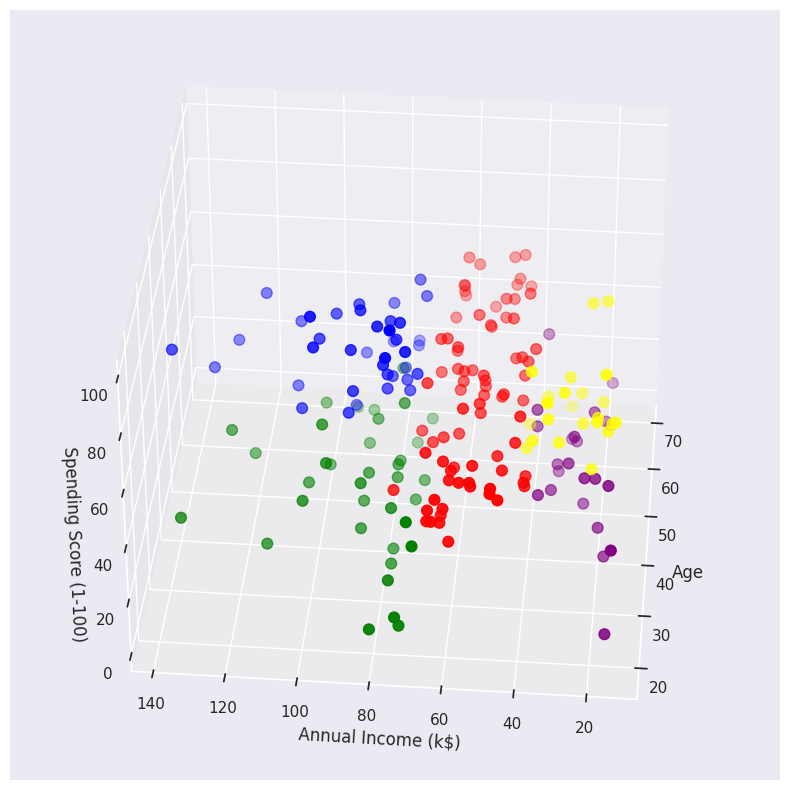

In [29]:
#3D Plot as we did the clustering on the basis of 3 input features
fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df1.Age[df1.label == 0], df1["Annual Income (k$)"][df1.label == 0], df1["Spending Score (1-100)"][df1.label == 0], c='purple', s=60)
ax.scatter(df1.Age[df1.label == 1], df1["Annual Income (k$)"][df1.label == 1], df1["Spending Score (1-100)"][df1.label == 1], c='red', s=60)
ax.scatter(df1.Age[df1.label == 2], df1["Annual Income (k$)"][df1.label == 2], df1["Spending Score (1-100)"][df1.label == 2], c='blue', s=60)
ax.scatter(df1.Age[df1.label == 3], df1["Annual Income (k$)"][df1.label == 3], df1["Spending Score (1-100)"][df1.label == 3], c='green', s=60)
ax.scatter(df1.Age[df1.label == 4], df1["Annual Income (k$)"][df1.label == 4], df1["Spending Score (1-100)"][df1.label == 4], c='yellow', s=60)
ax.view_init(35, 185)
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")
ax.set_zlabel('Spending Score (1-100)')
plt.show()

In [30]:

cust1=df1[df1["label"]==1]
print('Number of customer in 1st group=', len(cust1))
print('They are -', cust1["CustomerID"].values)
print("--------------------------------------------")
cust2=df1[df1["label"]==2]
print('Number of customer in 2nd group=', len(cust2))
print('They are -', cust2["CustomerID"].values)
print("--------------------------------------------")
cust3=df1[df1["label"]==0]
print('Number of customer in 3rd group=', len(cust3))
print('They are -', cust3["CustomerID"].values)
print("--------------------------------------------")
cust4=df1[df1["label"]==3]
print('Number of customer in 4th group=', len(cust4))
print('They are -', cust4["CustomerID"].values)
print("--------------------------------------------")
cust5=df1[df1["label"]==4]
print('Number of customer in 5th group=', len(cust5))
print('They are -', cust5["CustomerID"].values)
print("--------------------------------------------")

Number of customer in 1st group= 79
They are - [ 47  48  49  50  51  52  53  54  55  56  57  58  59  60  61  62  63  64
  65  66  67  68  69  70  71  72  73  74  75  76  77  78  79  80  81  82
  83  84  85  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100
 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118
 119 120 121 122 123 127 143]
--------------------------------------------
Number of customer in 2nd group= 39
They are - [124 126 128 130 132 134 136 138 140 142 144 146 148 150 152 154 156 158
 160 162 164 166 168 170 172 174 176 178 180 182 184 186 188 190 192 194
 196 198 200]
--------------------------------------------
Number of customer in 3rd group= 23
They are - [ 1  3  5  7  9 11 13 15 17 19 21 23 25 27 29 31 33 35 37 39 41 43 45]
--------------------------------------------
Number of customer in 4th group= 36
They are - [125 129 131 133 135 137 139 141 145 147 149 151 153 155 157 159 161 163
 165 167 169 171 173 175 177 179 181 183 185 187 18

## Understanding the clusters
The visuals below use the **Income vs Spending** clusters (`Cluster_2D`) because they are the easiest to explain to a business audience.

In [31]:
centers = km1.cluster_centers_          # [income, spending] per cluster
inc_mean, sp_mean = df1[INC].mean(), df1[SP].mean()

def name_cluster(income, spending, tol=0.2):
    hi_inc, lo_inc = income > inc_mean * (1 + tol), income < inc_mean * (1 - tol)
    hi_sp,  lo_sp  = spending > sp_mean * (1 + tol), spending < sp_mean * (1 - tol)
    if hi_inc and hi_sp: return 'Premium Spenders'
    if hi_inc and lo_sp: return 'Careful Wealthy'
    if lo_inc and hi_sp: return 'Impulsive Buyers'
    if lo_inc and lo_sp: return 'Budget Conscious'
    return 'Standard Customers'

segment_names = {i: name_cluster(*c) for i, c in enumerate(centers)}
df1['Segment'] = df1['Cluster_2D'].map(segment_names)
seg_colors = {'Premium Spenders': '#2ca02c', 'Careful Wealthy': '#1f77b4',
              'Impulsive Buyers': '#ff7f0e', 'Budget Conscious': '#d62728',
              'Standard Customers': '#9467bd'}
segment_names

{0: 'Standard Customers',
 1: 'Premium Spenders',
 2: 'Impulsive Buyers',
 3: 'Careful Wealthy',
 4: 'Budget Conscious'}

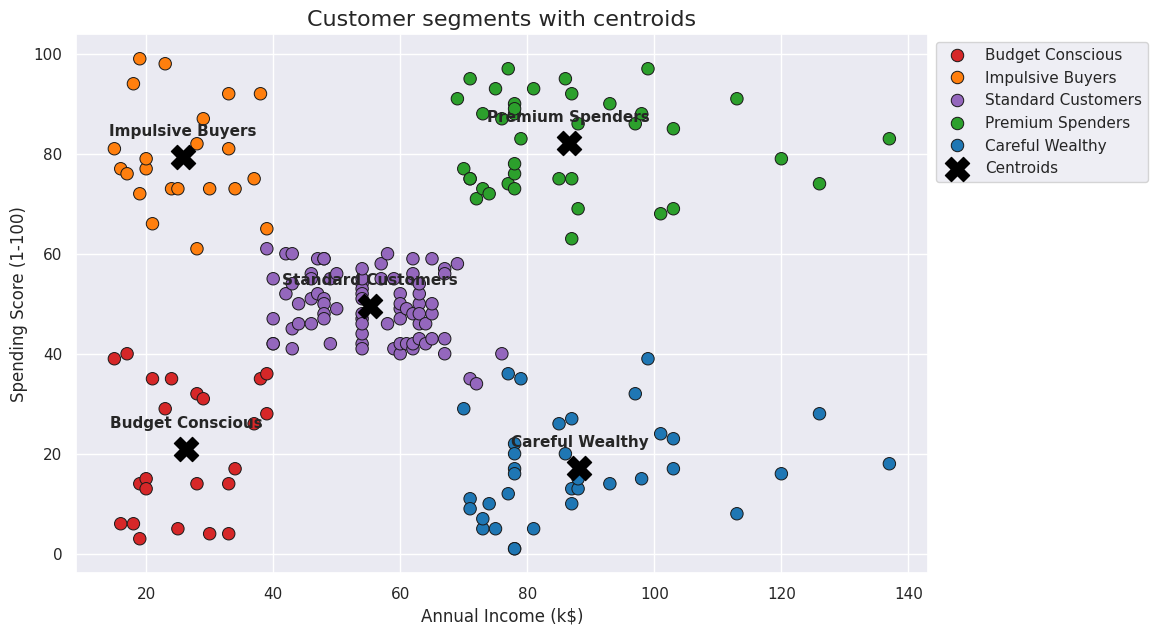

In [32]:
plt.figure(figsize=(11, 7))
sns.scatterplot(data=df1, x=INC, y=SP, hue='Segment', palette=seg_colors, s=80, edgecolor='k')
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=300, marker='X', label='Centroids')
for i, (cx, cy) in enumerate(centers):
    plt.annotate(segment_names[i], (cx, cy), textcoords='offset points', xytext=(0, 15),
                 ha='center', fontsize=11, fontweight='bold')
plt.title('Customer segments with centroids', fontsize=16)
plt.legend(bbox_to_anchor=(1, 1)); plt.show()

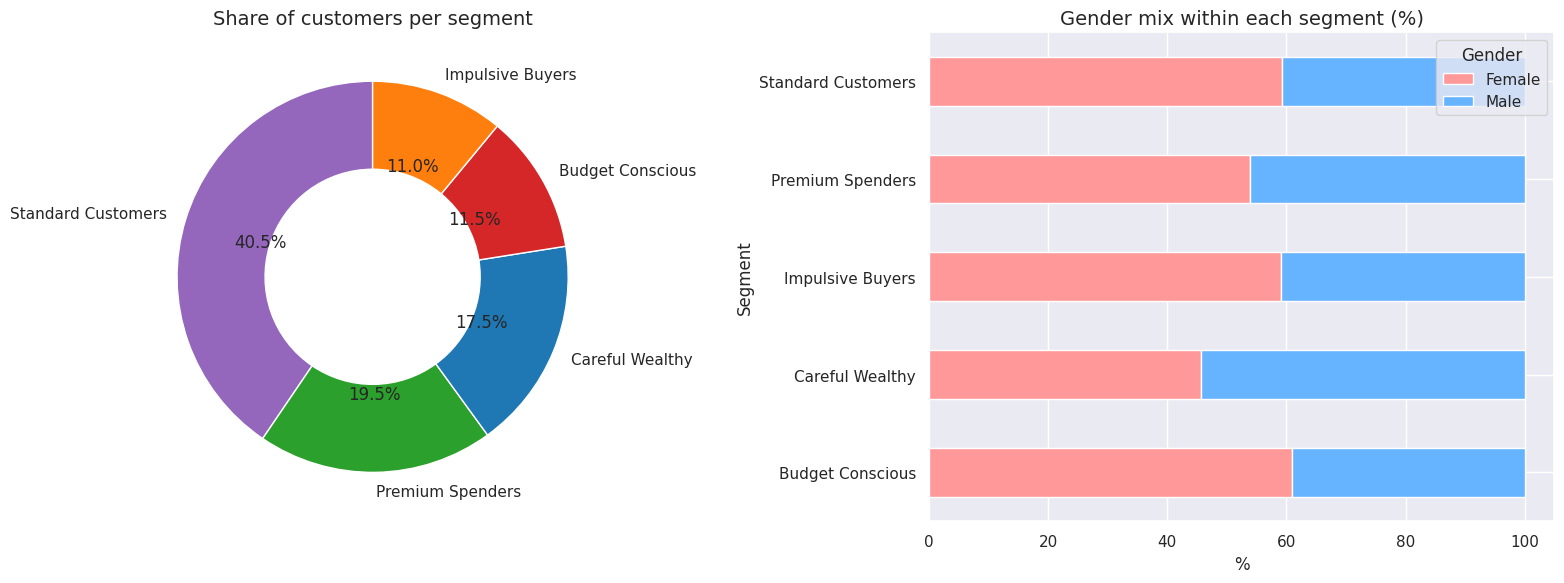

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
counts = df1['Segment'].value_counts()
axes[0].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90,
            colors=[seg_colors[s] for s in counts.index], wedgeprops={'width': 0.45})
axes[0].set_title('Share of customers per segment', fontsize=14)

pd.crosstab(df1['Segment'], df1['Gender'], normalize='index').mul(100).plot(
    kind='barh', stacked=True, ax=axes[1], color=['#ff9999', '#66b3ff'])
axes[1].set_title('Gender mix within each segment (%)', fontsize=14); axes[1].set_xlabel('%')
plt.tight_layout(); plt.show()

/tmp/ipykernel_573/693674040.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df1, x='Segment', y=col, palette=seg_colors, ax=ax)
/tmp/ipykernel_573/693674040.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df1, x='Segment', y=col, palette=seg_colors, ax=ax)
/tmp/ipykernel_573/693674040.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df1, x='Segment', y=col, palette=seg_colors, ax=ax)


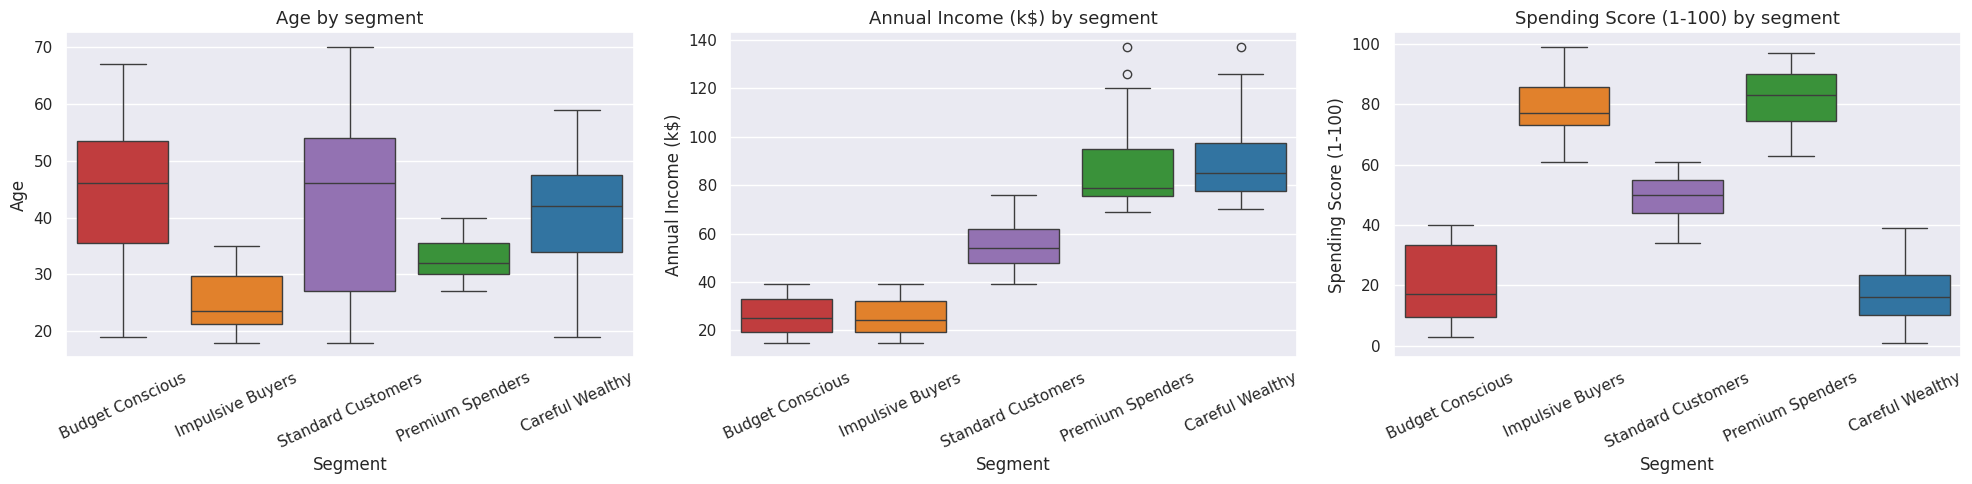

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df1, x='Segment', y=col, palette=seg_colors, ax=ax)
    ax.set_title(f'{col} by segment', fontsize=13); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

### Segment fingerprints — heatmap and radar chart

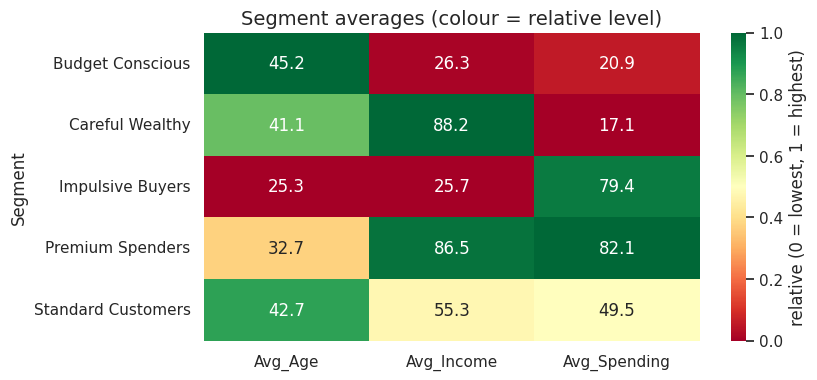

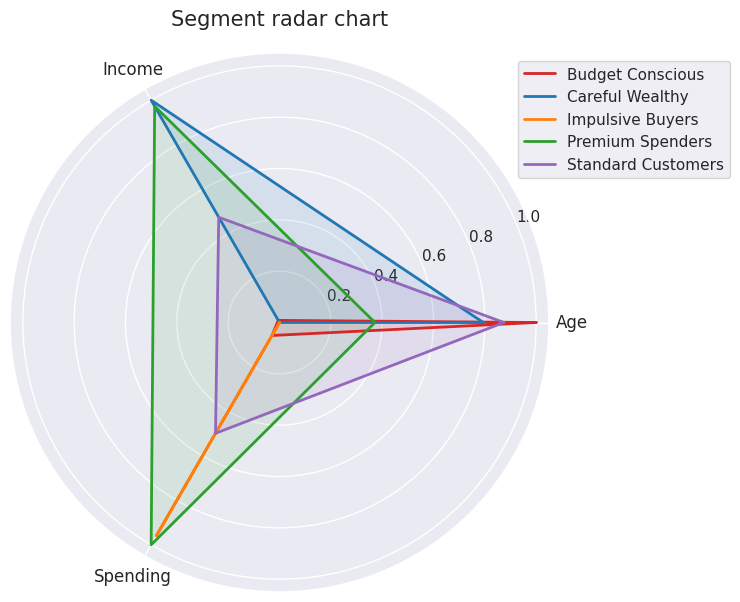

,Customers,Avg_Age,Avg_Income,Avg_Spending,Pct_Female
Segment,,,,,
Budget Conscious,23,45.2,26.3,20.9,60.9
Careful Wealthy,35,41.1,88.2,17.1,45.7
Impulsive Buyers,22,25.3,25.7,79.4,59.1
Premium Spenders,39,32.7,86.5,82.1,53.8
Standard Customers,81,42.7,55.3,49.5,59.3


In [35]:
profile = df1.groupby('Segment').agg(
    Customers=('CustomerID', 'count'), Avg_Age=('Age', 'mean'),
    Avg_Income=(INC, 'mean'), Avg_Spending=(SP, 'mean'),
    Pct_Female=('Gender', lambda g: (g == 'Female').mean() * 100)).round(1)

norm = (profile[['Avg_Age', 'Avg_Income', 'Avg_Spending']] -
        profile[['Avg_Age', 'Avg_Income', 'Avg_Spending']].min()) / \
       (profile[['Avg_Age', 'Avg_Income', 'Avg_Spending']].max() -
        profile[['Avg_Age', 'Avg_Income', 'Avg_Spending']].min())

plt.figure(figsize=(8, 4))
sns.heatmap(norm, annot=profile[['Avg_Age', 'Avg_Income', 'Avg_Spending']], fmt='.1f',
            cmap='RdYlGn', cbar_kws={'label': 'relative (0 = lowest, 1 = highest)'})
plt.title('Segment averages (colour = relative level)', fontsize=14); plt.show()

labels = ['Age', 'Income', 'Spending']
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist() + [0]
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(111, polar=True)
for seg, row in norm.iterrows():
    vals = row.tolist() + [row.iloc[0]]
    ax.plot(angles, vals, label=seg, color=seg_colors[seg], linewidth=2)
    ax.fill(angles, vals, color=seg_colors[seg], alpha=0.1)
ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels, fontsize=12)
ax.set_title('Segment radar chart', fontsize=15, pad=20)
plt.legend(bbox_to_anchor=(1.35, 1)); plt.show()
profile

### 3D clusters — interactive (drag to rotate)

In [36]:
import plotly.express as px
fig = px.scatter_3d(df1, x='Age', y=INC, z=SP, color=df1['Cluster_3D'].astype(str),
                    symbol='Gender', opacity=0.8, title='3D clusters: Age, Income, Spending')
fig.update_layout(legend_title_text='Cluster_3D', height=650)
fig.show()

df1.groupby('Cluster_3D')[['Age', INC, SP]].mean().round(1)

,Age,Annual Income (k$),Spending Score (1-100)
Cluster_3D,,,
0,45.2,26.3,20.9
1,43.1,55.3,49.6
2,32.7,86.5,82.1
3,40.7,87.8,17.6
4,25.5,26.3,78.6


## Power BI — exporting the results

Python does the clustering; Power BI turns the results into an interactive dashboard.
The cell below writes three files to `MyDrive/PowerBI_Customer_Segmentation/`:

| File | What it is |
|---|---|
| `customers_segmented.csv` | One row per customer: demographics, bands, cluster numbers, segment name (fact table) |
| `segment_summary.csv` | One row per segment: averages, size, marketing strategy (dimension table) |
| `segment_theme.json` | Power BI colour theme so each segment keeps the same colour as in this notebook |

In [37]:
import os, json
OUT_DIR = '/content/drive/MyDrive/PowerBI_Customer_Segmentation'
os.makedirs(OUT_DIR, exist_ok=True)

strategy = {
    'Premium Spenders':   'VIP loyalty programme, early access, premium brand partnerships',
    'Careful Wealthy':    'Highest untapped potential: quality/value messaging, personalised offers',
    'Impulsive Buyers':   'Flash sales, bundles, buy-now-pay-later',
    'Budget Conscious':   'Discount days, coupons, value product lines',
    'Standard Customers': 'Seasonal campaigns, points programme to move them up a tier',
}

# Fact table: one row per customer, friendly column names (no special characters)
customers = df1.rename(columns={INC: 'AnnualIncome_k', SP: 'SpendingScore'})[
    ['CustomerID', 'Gender', 'Age', 'AnnualIncome_k', 'SpendingScore',
     'Cluster_2D', 'Cluster_3D', 'Segment']].copy()
customers['AgeGroup'] = data['Age Group'].astype(str).values
customers['IncomeBand'] = data['Income Band'].astype(str).values
customers['SpendingCategory'] = data['Spending Category'].astype(str).values
customers.to_csv(f'{OUT_DIR}/customers_segmented.csv', index=False)

# Dimension table: one row per segment
summary = profile.reset_index()
summary['Share_pct'] = (summary['Customers'] / len(df1) * 100).round(1)
summary['Strategy'] = summary['Segment'].map(strategy)
summary['Color'] = summary['Segment'].map(seg_colors)
summary.to_csv(f'{OUT_DIR}/segment_summary.csv', index=False)

# Power BI theme (View → Themes → Browse for themes)
theme = {'name': 'Customer Segments', 'dataColors': list(seg_colors.values()),
         'background': '#FFFFFF', 'foreground': '#252423', 'tableAccent': '#1f77b4'}
with open(f'{OUT_DIR}/segment_theme.json', 'w') as f:
    json.dump(theme, f, indent=2)

print('Saved to', OUT_DIR); print(os.listdir(OUT_DIR))
customers.head()

Saved to /content/drive/MyDrive/PowerBI_Customer_Segmentation
['segment_rules.txt', 'customers_segmented.csv', 'segment_theme.json', 'segment_summary.csv']


,CustomerID,Gender,Age,AnnualIncome_k,SpendingScore,Cluster_2D,Cluster_3D,Segment,AgeGroup,IncomeBand,SpendingCategory
0,1,Male,19,15,39,4,0,Budget Conscious,18-25,<40k,Low (1-40)
1,2,Male,21,15,81,2,4,Impulsive Buyers,18-25,<40k,High (61-100)
2,3,Female,20,16,6,4,0,Budget Conscious,18-25,<40k,Low (1-40)
3,4,Female,23,16,77,2,4,Impulsive Buyers,18-25,<40k,High (61-100)
4,5,Female,31,17,40,4,0,Budget Conscious,26-35,<40k,Low (1-40)


In [38]:
# Optional: also download the files straight to your computer
from google.colab import files
for f in ['customers_segmented.csv', 'segment_summary.csv', 'segment_theme.json']:
    files.download(f'{OUT_DIR}/{f}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Power BI dashboard — as built (2 pages)

The two CSV files exported above are loaded into Power BI Desktop and linked on `Segment`:
`segment_summary[Segment]` (1) → `customers_segmented[Segment]` (many). Colours come from `segment_theme.json`.

### DAX measures (on `customers_segmented`)
```DAX
Total Customers = COUNTROWS(customers_segmented)
Avg Income      = AVERAGE(customers_segmented[AnnualIncome_k])
Avg Spending    = AVERAGE(customers_segmented[SpendingScore])
Avg Age         = AVERAGE(customers_segmented[Age])
```

### Page 1 — Overview
| Visual | Fields |
|---|---|
| 4 × Card | Total Customers, Avg Age, Avg Income, Avg Spending |
| Donut chart — *Total Customers by Segment* | Legend = Segment, Values = Total Customers |
| Clustered column chart — *Avg Spending by Age Group and Gender* | X-axis = AgeGroup, Y-axis = Avg Spending, Legend = Gender |
| Slicer | Gender |

### Page 2 — Segments
| Visual | Fields |
|---|---|
| Scatter chart — *Customer Segments: Income vs Spending* | X = AnnualIncome_k, Y = SpendingScore, Legend = Segment, Values = CustomerID (Don't summarize) |
| Matrix — segment averages | Rows = Segment; Values = Avg Spending, Avg Income, Avg Age, Total Customers |
| Table — marketing strategy | `segment_summary`: Segment, Share_pct, Strategy |
| 100% stacked bar — *Gender mix per segment* | Y-axis = Segment, Legend = Gender, X-axis = Total Customers |

### How the dashboard connects to this notebook
- The **Segment** names, colours and strategies are created in Python (sections *Understanding the clusters* and *Power BI — exporting the results*).
- The **Avg Income / Avg Spending / Avg Age** per segment in the Power BI matrix should match the `profile` table printed in the notebook. This is a quick check that the export worked correctly.
- Columns such as `Confidence`, `IsBorderline`, `UpsellTarget` and `RuleSegment` are exported too, and can be used to extend the dashboard later (e.g. an upsell-targets page).

### Saving and sharing
- **File → Save as** → `.pbix` (the editable, interactive report).
- **File → Export → Export to PDF** (a static copy). Clear all slicer selections first, so the PDF shows all 200 customers.